# 2. Injection des attaques de transmission (MITM et injection)

**Objectif.** Fabriquer le jeu de données d'étude : les traces réelles, dans lesquelles un attaquant
modifie les mesures **pendant leur trajet** entre le capteur et le broker MQTT. Le capteur fonctionne,
mais le serveur reçoit une fausse valeur.

| Scénario | Capteur visé | Ce que fait l'attaquant |
| --- | --- | --- |
| `MITM_gel` | frigo | répète la dernière valeur en boucle |
| `MITM_rejeu` | frigo | renvoie une fenêtre passée (au moins 1 h plus tôt) |
| `Injection_nominale` | frigo | envoie des valeurs forgées autour de 7 °C, peu bruitées |
| `Injection_biais_0.5` | frigo | décale toutes les mesures de −0,5 °C |
| `Injection_biais_1.0` | frigo | décale toutes les mesures de −1 °C |
| `Injection_biais_2.0` | frigo | décale toutes les mesures de −2 °C |
| `Injection_derive` | frigo | décale peu à peu, de 0 à −2 °C |
| `MITM_gel_thermostat` | salle | répète la dernière valeur |
| `Injection_biais_thermostat` | salle | décale de −1,5 °C |

> **Limite connue, gardée dans l'étude.** Les biais faibles `Injection_biais_0.5` (−0,5 °C) et
> `Injection_biais_1.0` (−1 °C) sont **sous le bruit du capteur** (σ ≈ 3,4 °C par mesure du frigo).
> On les garde : les résultats sont donnés **scénario par scénario**, et ces deux-là montrent ce que
> le système ne sait pas voir en 15 à 25 minutes. L'étude complémentaire
> `backend/scripts/transmission_biais_long.py` mesure à partir de quelle durée (1 à 3 h) ils
> deviennent détectables.

Le « masquage » (cacher une vraie hausse) est abandonné : ces traces n'ont pas d'excursion réelle à cacher.

In [18]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
# Evite les doublons de sys.path a chaque relance de la cellule.
for _p in (str(ROOT / "backend"), str(ROOT / "backend" / "scripts")):
    while _p in sys.path:
        sys.path.remove(_p)
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]

# Purge les modules importes depuis une autre copie du projet (sinon
# Python reutilise un ancien app.core.paths sans RESULTS_COMPARISON).
for _m in [m for m in list(sys.modules)
           if m == "app" or m.startswith("app.")
           or m in ("build_dataset", "transmission_real",
                    "transmission_models", "transmission_study",
                    "train_models")]:
    del sys.modules[_m]

# Reset du metadata SQLModel : sinon, reimporter les modeles (users,
# ml_models, model_metrics) leve une erreur Table deja definie.
try:
    import sqlmodel as _sqlmodel
    _sqlmodel.SQLModel.metadata.clear()
except Exception:
    pass

# Detecte un noyau corrompu par une interruption pendant l'import de
# scikit-learn (KeyError __reduce_cython__) : seul un redemarrage repare.
try:
    from sklearn.ensemble import ExtraTreesClassifier as _etc  # noqa: F401
except KeyError as _e:
    raise RuntimeError(
        "Noyau Jupyter corrompu : scikit-learn a ete interrompu pendant son "
        "import. Redemarre le noyau (Kernel > Restart Kernel), puis relance "
        "cette cellule."
    ) from _e

import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.domains.ml import pipeline
from app.core import paths

# Deduplique sys.path : chaque module du projet reinsere son dossier.
_seen = set()
_clean = []
for _p in sys.path:
    if _p not in _seen:
        _seen.add(_p)
        _clean.append(_p)
sys.path[:] = _clean

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"

In [19]:
base = pd.read_csv(paths.PROCESSED_DIR / "traces_reelles_5s.csv", parse_dates=["datetime"])
base["fridge_cond"] = base["fridge_cond"].astype(str)
print(f"{len(base):,} lignes de traces réelles fusionnées")

44,443 lignes de traces réelles fusionnées


## 2.1 Découpage en blocs, zone de garde et planning des attaques

- **Le découpage train/val/test n'est pas stocké dans le jeu de données.** Il est calculé
  **au moment de l'entraînement** (fonction `transmission_real.block_split`), de façon
  **non aléatoire** : les heures sont découpées en **blocs d'une heure** attribués selon un
  motif fixe de **70 % train / 15 % val / 15 % test** (14 train / 3 val / 3 test sur un cycle
  de 20 blocs). Une attaque tient **entièrement** dans un bloc → **aucune attaque n'est
  coupée** entre deux rôles.
- **Zone de garde de 20 minutes** (`tr.GUARD` = 240 pas), plus longue que la plus longue fenêtre
  glissante des features (15 min) augmentée de la règle de persistance des alertes (3 min au plus) :
  - **après chaque épisode** : les fenêtres glissantes « traînent » encore l'attaque pendant 15 min ;
    ces lignes, étiquetées normales mais calculées avec des valeurs falsifiées, ne sont ni apprises ni
    évaluées ;
  - **au début de chaque bloc qui change de rôle** (train → val, val → test, test → train) : la
    fenêtre d'une ligne de début de bloc contiendrait des mesures d'un autre rôle (fuite) ; ces lignes
    sont exclues, et les épisodes de ces blocs commencent après la zone de garde.
  Version précédente : 5 minutes seulement après les épisodes, plus courte que la fenêtre de 15 min
  (remarque du professeur).
- **Train** : un **épisode d'attaque de 15 à 25 minutes** dans **chaque bloc** : les modèles supervisés
  ont assez d'exemples d'attaque pour apprendre.
- **Validation et test** : un épisode dans **2 blocs sur 5** seulement, une proportion **réaliste**
  (la précision dépend directement de la part d'attaques).
- Les scénarios se suivent en boucle, pour que chacun apparaisse dans chaque rôle.

In [20]:
rng = np.random.default_rng(SEED)
episodes = tr.build_schedule(len(base), rng, run=0, roles=("train", "val", "test"))
plan = pd.DataFrame(episodes)
plan["début"] = base["datetime"].iloc[plan["start"]].values
plan["durée (min)"] = (plan["end"] - plan["start"]) * 5 / 60
plan[["name", "sensor", "kind", "param", "split", "début", "durée (min)"]]

,name,sensor,kind,param,split,début,durée (min)
0,MITM_gel,fridge,gel,NaN,train,2019-04-01 14:58:25,16.416667
1,MITM_rejeu,fridge,rejeu,NaN,train,2019-04-01 16:01:05,19.416667
2,Injection_nominale,fridge,nominale,NaN,train,2019-04-01 17:04:55,18.416667
3,Injection_biais_0.5,fridge,biais,-0.5,train,2019-04-01 17:58:55,24.750000
4,Injection_biais_1.0,fridge,biais,-1.0,train,2019-04-01 19:12:50,17.000000
5,Injection_biais_2.0,fridge,biais,-2.0,train,2019-04-01 19:54:50,19.333333
6,Injection_derive,fridge,derive,-2.0,train,2019-04-01 20:52:00,19.583333
7,MITM_gel_thermostat,thermostat,gel,NaN,train,2019-04-01 22:19:35,21.500000
8,Injection_biais_thermostat,thermostat,biais,-1.5,train,2019-04-01 23:04:10,21.916667
9,MITM_gel,fridge,gel,NaN,train,2019-04-02 00:12:20,20.333333


In [21]:
df = tr.inject(base, episodes, rng, run=0)
# Le découpage train/val/test n'est PAS stocké dans le dataset : on le recalcule ici
# (non aléatoire, 70/15/15, par blocs d'une heure) rien que pour lire le bilan.
role = tr.block_split(len(df), run=0)
exclu = tr.excluded_rows(df["garde"].to_numpy(), run=0)   # zone de garde : après les épisodes + début de bloc
evalue = ~exclu
bilan = df[evalue].groupby(role[evalue])["label"].agg(lignes="size", attaques="sum")
bilan["part d'attaques"] = (100 * bilan["attaques"] / bilan["lignes"]).round(1).astype(str) + " %"
bilan["épisodes"] = [sum(e["split"] == r for e in episodes) for r in bilan.index]
bilan["exclues (zone de garde)"] = [int((exclu & (role == r)).sum()) for r in bilan.index]
bilan

,lignes,attaques,part d'attaques,épisodes,exclues (zone de garde)
test,4819,1107,23.0 %,4,1661
train,20592,10070,48.9 %,43,10891
val,4994,1009,20.2 %,4,1486


### Vérification de la zone de garde

Le test automatique `test_no_feature_window_crosses_a_role_boundary_or_an_episode` (pytest) fait la même
vérification sur 4 rotations du découpage.

In [22]:
# Vérification : aucune ligne gardée n'a une fenêtre de 20 min (≥ 15 min de features + 3 min de
# persistance) qui touche un autre rôle, et aucune ligne normale gardée ne voit un épisode dans sa fenêtre.
code_role = np.unique(role, return_inverse=True)[1]
lab = df["label"].to_numpy()
cum = np.concatenate([[0], np.cumsum(lab)])
gardees = np.where(evalue)[0]
gardees = gardees[gardees >= tr.GUARD]
fenetre_mixte = sum((code_role[t - tr.GUARD + 1:t + 1] != code_role[t]).any() for t in gardees)
normales = gardees[lab[gardees] == 0]
voit_attaque = int((cum[normales + 1] - cum[normales + 1 - tr.GUARD] > 0).sum())
print(f"zone de garde : {tr.GUARD} pas = {tr.GUARD * 5 / 60:.0f} min ; plus longue fenêtre : {tr.W_MAX * 5 / 60:.0f} min")
print(f"lignes gardées dont la fenêtre traverse une frontière de rôle : {fenetre_mixte}")
print(f"lignes normales gardées qui voient un épisode dans leur fenêtre : {voit_attaque}")
assert fenetre_mixte == 0 and voit_attaque == 0

zone de garde : 240 pas = 20 min ; plus longue fenêtre : 15 min
lignes gardées dont la fenêtre traverse une frontière de rôle : 0
lignes normales gardées qui voient un épisode dans leur fenêtre : 0


## 2.2 À quoi ressemble chaque attaque ?

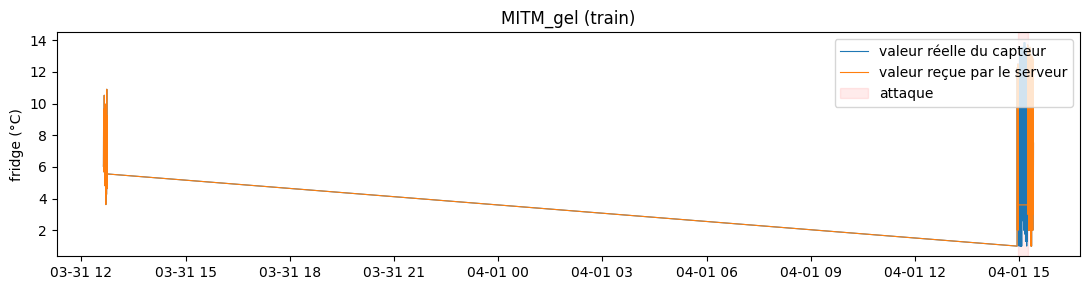

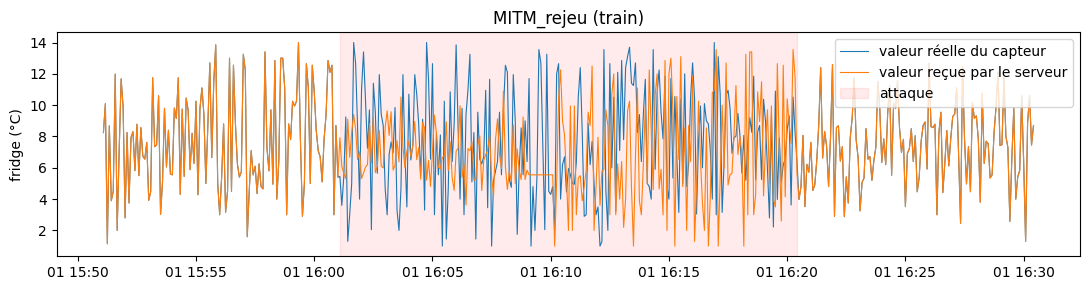

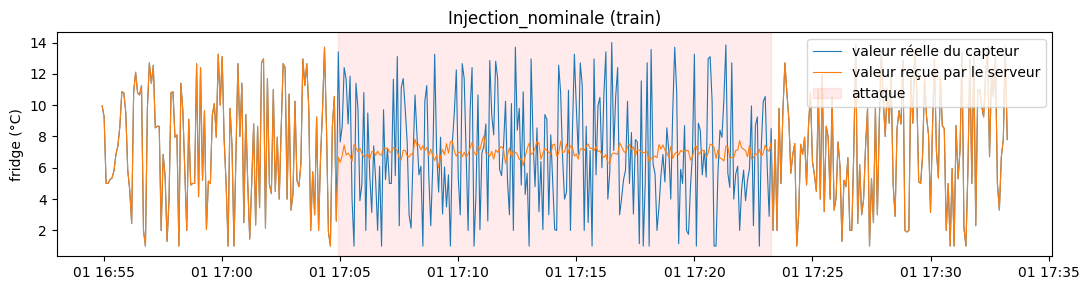

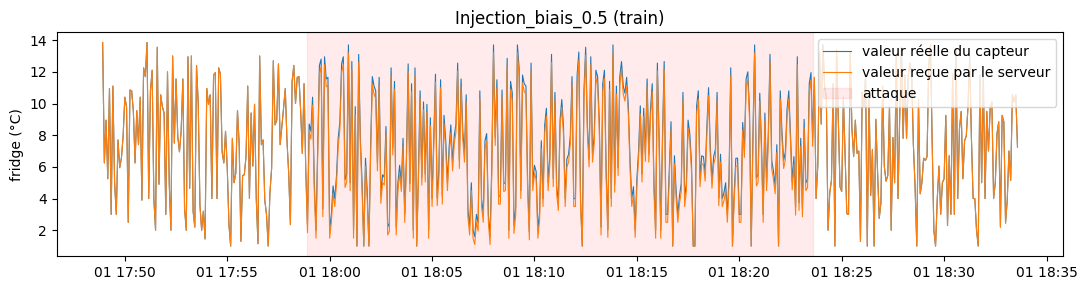

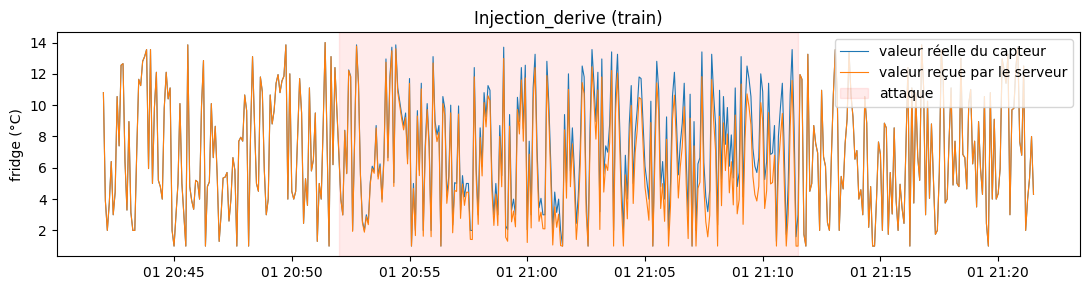

In [23]:
def montrer(kind, marge=120):
    ep = next(e for e in episodes if e["kind"] == kind)
    col = "fridge" if ep["sensor"] == "fridge" else "thermostat"
    a, b = ep["start"] - marge, ep["end"] + marge
    t = df["datetime"].iloc[a:b]
    plt.figure(figsize=(11, 3))
    plt.plot(t, df[f"{col}_true"].iloc[a:b], lw=0.8, label="valeur réelle du capteur")
    plt.plot(t, df[f"{col}_temp"].iloc[a:b], lw=0.8, label="valeur reçue par le serveur")
    plt.axvspan(df["datetime"].iloc[ep["start"]], df["datetime"].iloc[ep["end"] - 1], color="red", alpha=0.08, label="attaque")
    plt.title(f"{ep['name']} ({ep['split']})"); plt.ylabel(f"{col} (°C)"); plt.legend(loc="upper right"); plt.tight_layout()

for kind in ("gel", "rejeu", "nominale", "biais", "derive"):
    montrer(kind)

Le gel et l'injection nominale se voient à l'œil : la mesure ne bouge plus, ou devient trop
régulière. Le rejeu et les biais sont invisibles à l'œil : les valeurs rejouées ou décalées ont
la même allure que les vraies. Seul un calcul (niveau moyen, séquence déjà vue) peut les repérer.

## 2.3 Features et enregistrement du jeu de données

In [24]:
df, feats = tm.engineer(df)
df.to_csv(tr.DATASET_PATH, index=False, float_format="%.4f")
with open(EPISODES_PATH, "w", encoding="utf-8") as f:
    json.dump(episodes, f, indent=1)
print("Jeu de données :", tr.DATASET_PATH, f"({len(df):,} lignes, {len(feats)} features)")
print("Planning des attaques :", EPISODES_PATH, f"({len(episodes)} épisodes)")

Jeu de données : C:\Users\User\Downloads\Projet_fin_d'étude\VigiloChain\VigiloChain\surveillance-produits-pharmaceutiques-meriem\data\processed\dataset_transmission_reel.csv (44,443 lignes, 53 features)
Planning des attaques : C:\Users\User\Downloads\Projet_fin_d'étude\VigiloChain\VigiloChain\surveillance-produits-pharmaceutiques-meriem\data\processed\episodes_transmission_reel.json (51 épisodes)


Ce fichier correspond à la **répétition 0** de l'étude. Comme les traces ne durent que 62 heures,
le script `backend/scripts/transmission_models.py` rejoue **20 fois** ce découpage en décalant le cycle
de 20 blocs d'un cran à chaque fois : les 20 rotations sont parcourues, **chaque heure sert 3 fois de
test et 3 fois de validation**, et les scénarios tournent aussi. Les résultats sont cumulés. Les
notebooks suivants travaillent sur la répétition 0 et affichent aussi le résultat cumulé.